## Tutorial: Interaction of co-spatial blobs
Consider the case of two co-spatial blobs in the jet, following the model presented in [(Tavecchio F. et al 2011)](https://ui.adsabs.harvard.edu/abs/2011A%26A...534A..86T/abstract).  
The electrons from one blob can up-scatter the synchrotron photons produced in the other blob, and viceversa. 

In this tutorial, we will show how to compute the Spectral Energy Distribution term due to the inverse-Compton scattering of the electrons of one blob with the synchrotron photons of the other blob. In addition, we will reproduce the two-component SEDs in Figure 8 of [(MAGIC Collaboration et al. 2020)](https://ui.adsabs.harvard.edu/abs/2020A%26A...640A.132M/abstract).

In [1]:
# import numpy, astropy and matplotlib for basic functionalities
from pathlib import Path
import numpy as np
import astropy.units as u
from astropy.constants import m_e
from astropy.table import Table
import pkg_resources
import matplotlib.pyplot as plt
plt.rc("font", size = 18)
from matplotlib.lines import Line2D
from IPython.display import Image

# import agnpy classes
from agnpy.spectra import SmoothBrokenPowerLaw
from agnpy.emission_regions import Blob
from agnpy.synchrotron import Synchrotron
from agnpy.compton import SynchrotronSelfCompton, InteractingBlobs
from agnpy.utils.plot import load_mpl_rc

import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

/tmp/ipykernel_74325/2615647834.py:7: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


Read the SED model parameters from Table 6 of [(MAGIC Collaboration et al. 2020)](https://ui.adsabs.harvard.edu/abs/2020A%26A...640A.132M/abstract)

In [2]:
sed_path = pkg_resources.resource_filename("agnpy", "data/sed_params/magic2020/sed_models.ecsv")

table = Table.read(sed_path, format="ascii.ecsv")
table

source,component,z,gamma_min,gamma_b,gamma_max,p1,p2,B,K,R_b,delta_D,Gamma
,,,,,,,,G,1 / cm3,cm,,
str33,str4,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
VER J0521+211,blob,0.18,1000.0,30000.0,400000.0,1.95,3.1,0.1,31500.0,1.3e+16,12.0,12.0
VER J0521+211,core,0.18,350.0,1100.0,16000.0,1.64,2.77,0.1,12.0,3.7e+17,11.0,11.0
PKS 1424+240 (2014),blob,0.604,9000.0,32000.0,300000.0,1.98,3.35,0.1,17000.0,1.9e+16,20.0,20.0
PKS 1424+240 (2014),core,0.604,350.0,3000.0,28000.000000000004,1.69,3.0,0.1,7.0,1.02e+18,10.0,10.0
PKS 1424+240 (2015),blob,0.604,6000.0,45000.0,330000.0,1.98,3.85,0.1,32000.0,1.31e+16,18.0,18.0
PKS 1424+240 (2015),core,0.604,330.0,3000.0,30000.0,1.68,3.0,0.1,7.0,1.02e+18,10.0,10.0
1ES 1727+502,blob,0.055,5000.0,50000.0,1300000.0,1.95,2.45,0.1,7000.0,7100000000000000.0,11.0,11.0
1ES 1727+502,core,0.055,160.0,3000.0,80000.0,1.95,2.7,0.1,150.0,1.54e+17,4.0,4.0


For each source state, we now compute the SED terms corresponding to the synchrotron, SSC, and interaction components.  
We then store all these components in a dictionary to plot them later.

In [3]:
nu = np.logspace(8, 29, 200) * u.Hz
ssa = True

sources = list(dict.fromkeys(table["source"]))
component_names = ["blob", "core"]

dictionary = {}

for source in sources:

    dictionary[source] = {}

    for component_name in component_names:

        dictionary[source][component_name] = {}

        mask = (
            (table["source"] == source)
            & (table["component"] == component_name)
        )
        component = table[mask]

        n_e = SmoothBrokenPowerLaw(
            k = component["K"].quantity[0],
            p1 = component["p1"].value[0], 
            p2 = component["p2"].value[0], 
            gamma_b = component["gamma_b"].value[0], 
            gamma_min = component["gamma_min"].value[0], 
            gamma_max = component["gamma_max"].value[0]
        )
        region = Blob(
            R_b = component["R_b"].quantity[0],
            z = component["z"].value[0],
            delta_D = component["delta_D"].value[0],
            B = component["B"].quantity[0],
            n_e = n_e
        )
        synch = Synchrotron(region, ssa = ssa)
        ssc = SynchrotronSelfCompton(region)

        dictionary[source][component_name] = {
            "Region": region,
            "Synchrotron": synch.sed_flux(nu),
            "SSC": ssc.sed_flux(nu)
        }

    # Compute interaction term
    int_blobs = InteractingBlobs(
        blob_e = dictionary[source]["blob"]["Region"],
        blob_t = dictionary[source]["core"]["Region"]
    )
    int_sed = int_blobs.sed_flux(nu)
    dictionary[source]["Interaction"] = int_sed

We plot now all the SEDs and compare them visually with Figure 8 in [(MAGIC Collaboration et al. 2020)](https://ui.adsabs.harvard.edu/abs/2020A%26A...640A.132M/abstract)

In [4]:
def plot_sed_2zones (ax, nu, blob_sed, core_sed, interaction_sed, label):
    ax.loglog(nu, blob_sed, label = "Blob", color = "tab:red", ls = "dashdot", lw = 3)
    ax.loglog(nu, core_sed, label = "Core", color = "violet", ls = "dashed", lw = 3)
    ax.loglog(nu, interaction_sed, label = "Interaction", color = "tab:blue", ls = "dashed", lw = 3)
    ax.loglog(nu, blob_sed + core_sed + interaction_sed, label = "Total", color = "black", ls = "solid", lw = 3)
    ax.text(0.05, 0.85, label, transform = ax.transAxes, fontsize = "medium", bbox=dict(facecolor='white', alpha=1., edgecolor = "white"))
    ax.grid(lw = 1.0, color = "gainsboro")
    return ax

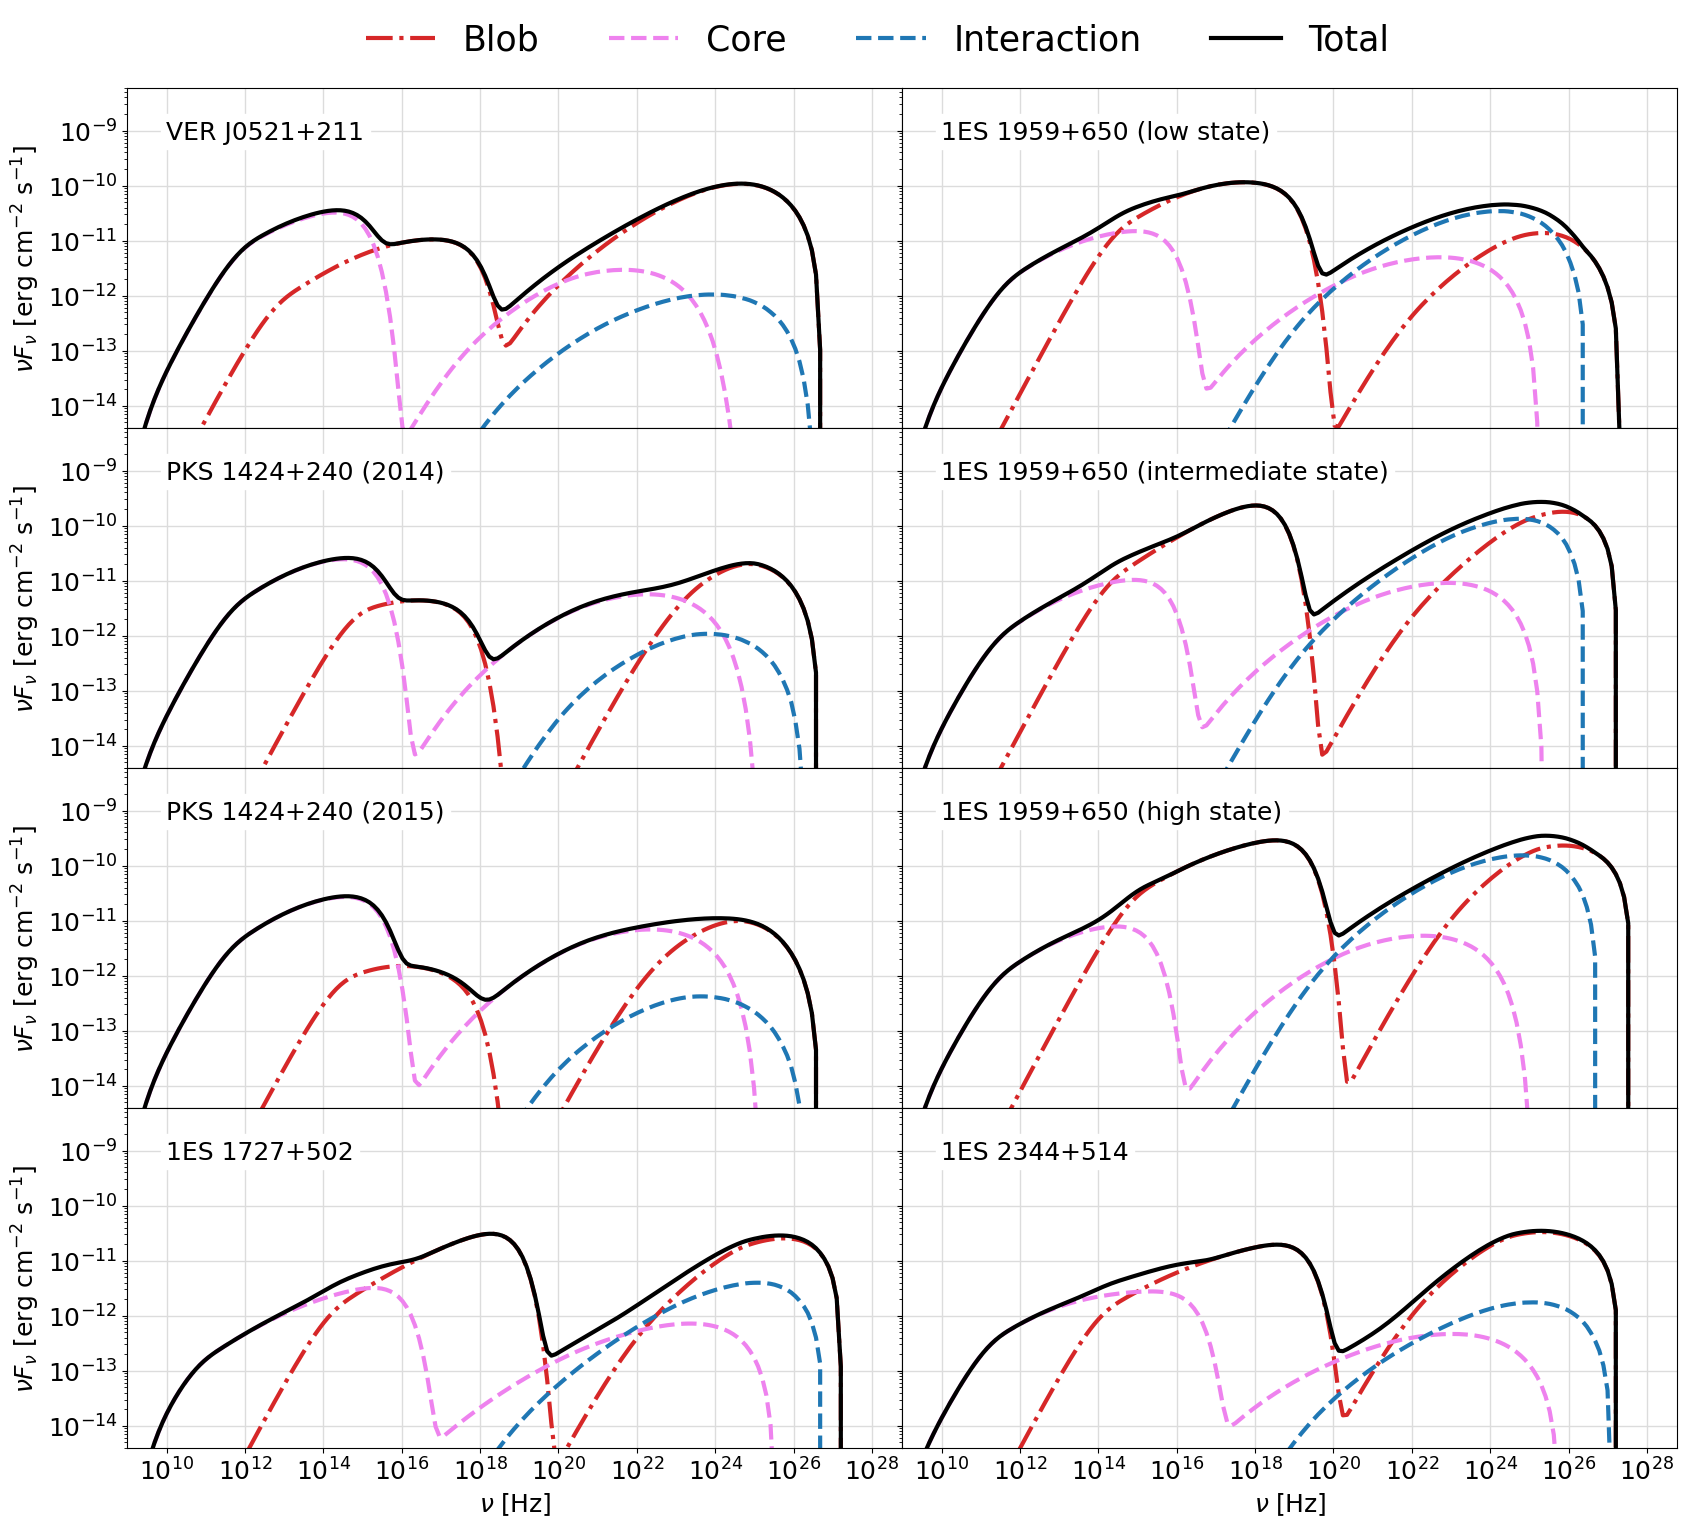

In [5]:
fig, axs = plt.subplots(4, 2, figsize = (20, 16), sharex = True, sharey = True)
fig.subplots_adjust(hspace = 0, wspace = 0)

for i, source in enumerate(sources):
    ax = plot_sed_2zones(axs.T.flatten()[i], 
                         nu,
                         dictionary[source]["blob"]["Synchrotron"] + dictionary[source]["blob"]["SSC"], 
                         dictionary[source]["core"]["Synchrotron"] + dictionary[source]["core"]["SSC"], 
                         dictionary[source]["Interaction"], 
                         label=source)

ax = axs[0,0]
ax.set_xlim(1e9, 6e28)
ax.set_ylim(bottom = 4e-15, top = 6e-9)
ax.set_yticks([1e-14, 1e-13, 1e-12, 1e-11, 1e-10, 1e-9])
ax.set_xticks([1e10, 1e12, 1e14, 1e16, 1e18, 1e20, 1e22, 1e24, 1e26, 1e28]);

# Axis labels
axs[-1, 0].set_xlabel("$\\nu$ [Hz]")
axs[-1, 1].set_xlabel("$\\nu$ [Hz]")

for i in range(4):
    axs[i, 0].set_ylabel("$\\nu F_{\\nu}$ [erg cm$^{-2}$ s$^{-1}$]");

# Unique legend for all subplots
legend_elements = [
    Line2D([0], [0], color="tab:red", ls="dashdot", lw = 3, label="Blob"),
    Line2D([0], [0], color="violet", ls="dashed", lw = 3, label="Core"),
    Line2D([0], [0], color="tab:blue", ls="dashed", lw = 3, label="Interaction"),
    Line2D([0], [0], color="black", lw=3, label="Total")
]
fig.legend(
    handles=legend_elements,
    loc="upper center", bbox_to_anchor=(0.5, 1.02), ncol=len(legend_elements),
    fontsize=25, frameon=False,
)
fig.subplots_adjust(top=0.96);

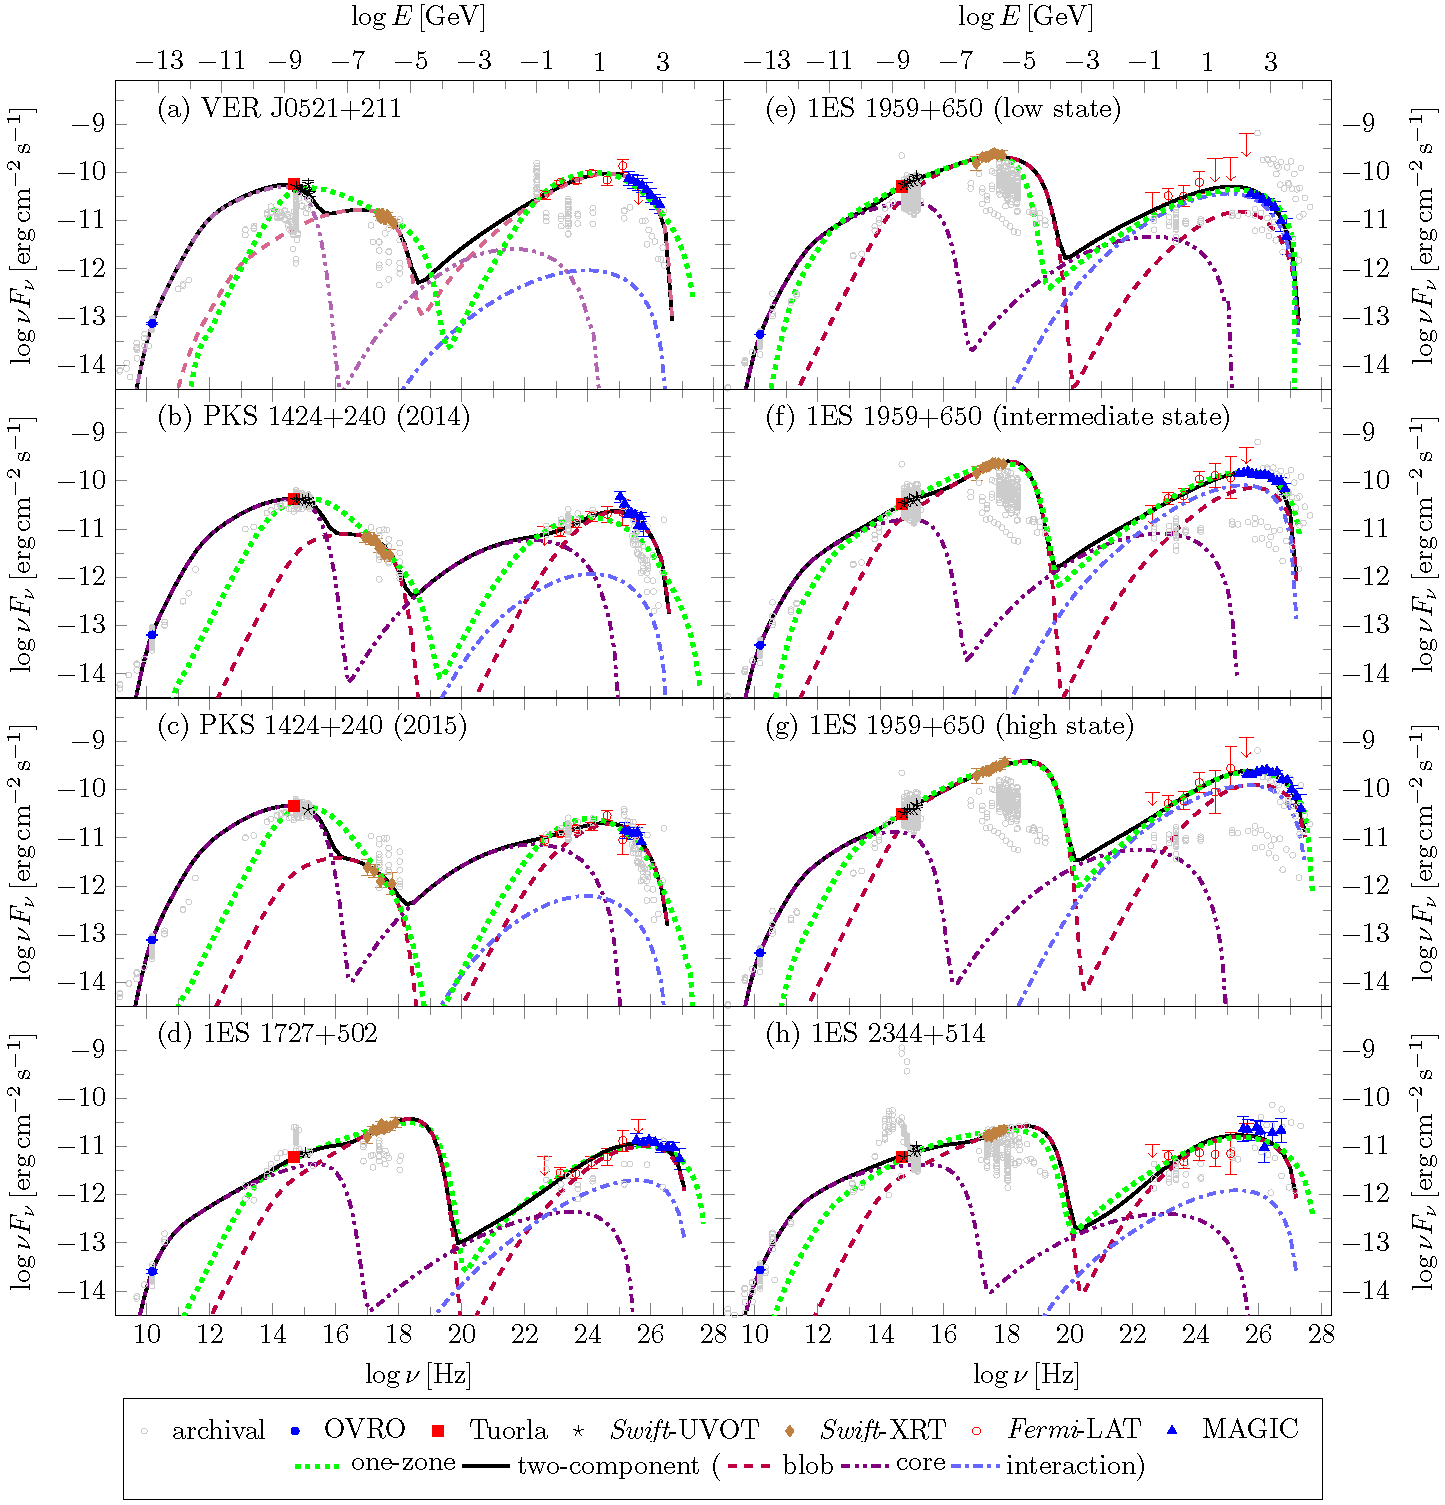

In [6]:
Image("figures/figure_8_magic_2020.png", width=1000, height=600)